In [1]:
!pip install pandas numpy matplotlib seaborn openpyxl scikit-learn mlxtend

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

folder = r"D:\Sagha Documents\Retail_Analytics_Project"

print("Project folder:")
print(folder)

print("\nFiles in project folder:")

for file in os.listdir(folder):
    print(file)

Project folder:
D:\Sagha Documents\Retail_Analytics_Project

Files in project folder:
.ipynb_checkpoints
Online Retail.xlsx
online+retail.zip
Retail_Analytics.ipynb


In [4]:
file_path = r"D:\Sagha Documents\Retail_Analytics_Project\Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 541909
Columns: 8


In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [8]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [10]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:
missing_values = df.isnull().sum()

missing_values

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [12]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [13]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 5268


In [14]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))

Original rows: 541909
Rows after removing duplicates: 536641


In [15]:
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

In [16]:
cancelled_transactions = df_clean[
    df_clean["InvoiceNo"].str.startswith("C")
]

print(
    "Cancelled transaction rows:",
    len(cancelled_transactions)
)

Cancelled transaction rows: 9251


In [17]:
cancelled_transactions.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [18]:
df_clean = df_clean[
    ~df_clean["InvoiceNo"].str.startswith("C")
].copy()

print(
    "Rows after removing cancelled transactions:",
    len(df_clean)
)

Rows after removing cancelled transactions: 527390


In [19]:
print(
    "Quantity <= 0:",
    (df_clean["Quantity"] <= 0).sum()
)

Quantity <= 0: 1336


In [20]:
df_clean = df_clean[
    df_clean["Quantity"] > 0
].copy()

print(
    "Rows after quantity cleaning:",
    len(df_clean)
)

Rows after quantity cleaning: 526054


In [21]:
print(
    "UnitPrice <= 0:",
    (df_clean["UnitPrice"] <= 0).sum()
)

UnitPrice <= 0: 1176


In [22]:
df_clean = df_clean[
    df_clean["UnitPrice"] > 0
].copy()

print(
    "Rows after price cleaning:",
    len(df_clean)
)

Rows after price cleaning: 524878


In [23]:
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

print(df_clean["InvoiceDate"].dtype)

datetime64[us]


In [24]:
print(
    "Missing Customer IDs:",
    df_clean["CustomerID"].isnull().sum()
)

Missing Customer IDs: 132186


In [25]:
df_customer = df_clean.dropna(
    subset=["CustomerID"]
).copy()

print(
    "Rows available for customer analysis:",
    len(df_customer)
)

Rows available for customer analysis: 392692


In [26]:
df_clean["Revenue"] = (
    df_clean["Quantity"] *
    df_clean["UnitPrice"]
)

In [27]:
df_clean[
    ["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]
].head(10)

,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08


In [28]:
total_revenue = df_clean["Revenue"].sum()

print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £10,642,110.80


In [29]:
total_orders = df_clean["InvoiceNo"].nunique()

print("Total Orders:", total_orders)

Total Orders: 19960


In [30]:
total_customers = df_customer["CustomerID"].nunique()

print("Total Customers:", total_customers)

Total Customers: 4338


In [31]:
total_products = df_clean["StockCode"].nunique()

print("Total Products:", total_products)

Total Products: 3922


In [32]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Products"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        total_products
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,1.064211e+07
1,Total Orders,1.996000e+04
2,Total Customers,4.338000e+03
3,Total Products,3.922000e+03


In [33]:
cleaned_file = r"D:\Sagha Documents\Retail_Analytics_Project\retail_cleaned_data.csv"

df_clean.to_csv(
    cleaned_file,
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [34]:
df_clean["Date"] = df_clean["InvoiceDate"].dt.date

df_clean[["InvoiceDate", "Date"]].head()

,InvoiceDate,Date
0,2010-12-01 08:26:00,2010-12-01
1,2010-12-01 08:26:00,2010-12-01
2,2010-12-01 08:26:00,2010-12-01
3,2010-12-01 08:26:00,2010-12-01
4,2010-12-01 08:26:00,2010-12-01


In [35]:
daily_revenue = (
    df_clean
    .groupby("Date")["Revenue"]
    .sum()
)

daily_revenue.head()

Date
2010-12-01    58776.79
2010-12-02    47629.42
2010-12-03    46898.63
2010-12-05    31364.63
2010-12-06    54624.15
Name: Revenue, dtype: float64

In [36]:
best_day = daily_revenue.idxmax()
best_day_revenue = daily_revenue.max()

print("Best Sales Day:", best_day)
print(f"Revenue: £{best_day_revenue:,.2f}")

Best Sales Day: 2011-12-09
Revenue: £200,900.98


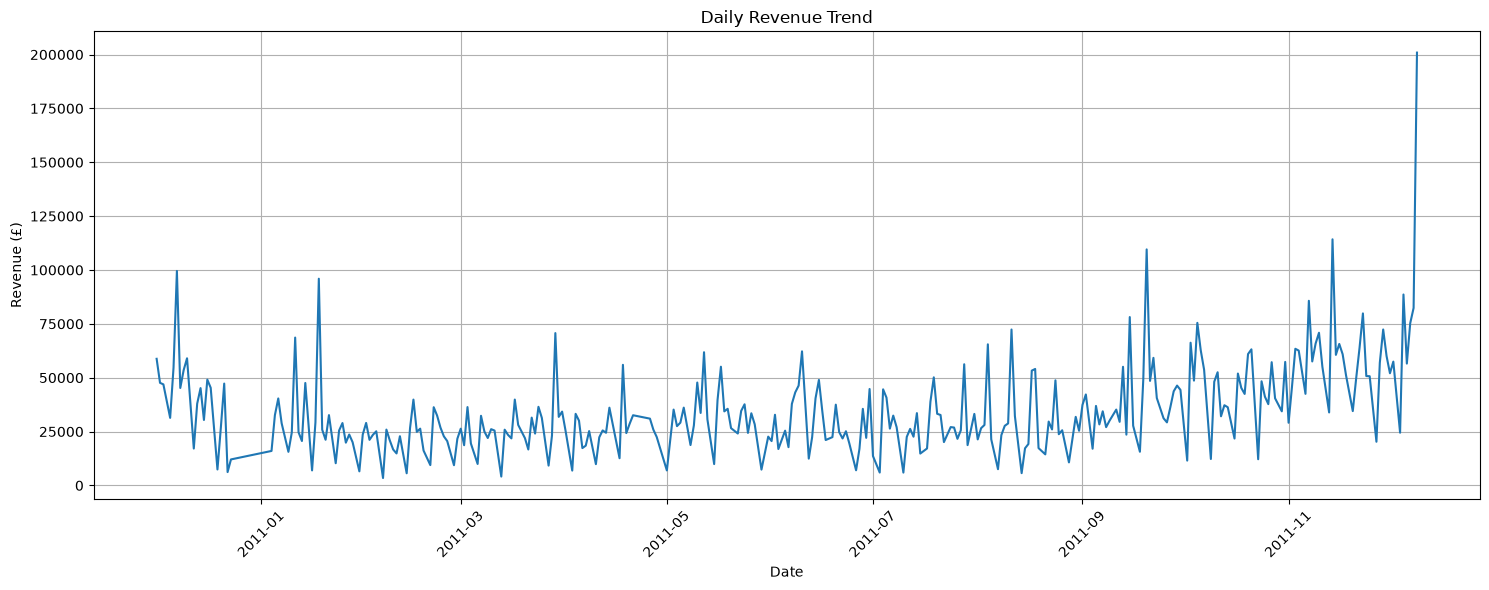

In [37]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_revenue.index,
    daily_revenue.values
)

plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [38]:
df_clean["Month"] = (
    df_clean["InvoiceDate"]
    .dt.to_period("M")
)

In [39]:
df_clean[
    ["InvoiceDate", "Month"]
].head()

,InvoiceDate,Month
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [40]:
monthly_revenue = (
    df_clean
    .groupby("Month")["Revenue"]
    .sum()
)

monthly_revenue

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

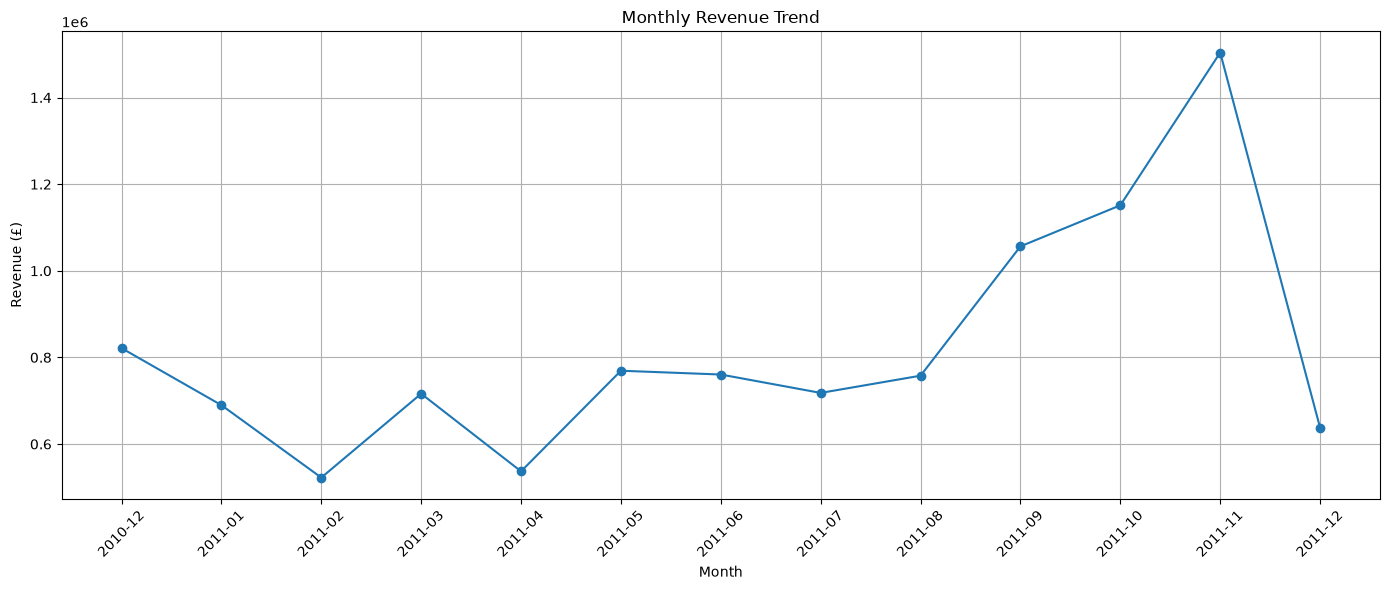

In [41]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [42]:
best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()

print("Best Month:", best_month)
print(
    f"Revenue: £{best_month_revenue:,.2f}"
)

Best Month: 2011-11
Revenue: £1,503,866.78


In [43]:
worst_month = monthly_revenue.idxmin()
worst_month_revenue = monthly_revenue.min()

print("Lowest Revenue Month:", worst_month)
print(
    f"Revenue: £{worst_month_revenue:,.2f}"
)

Lowest Revenue Month: 2011-02
Revenue: £522,545.56


In [44]:
top_products_quantity = (
    df_clean
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_quantity

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

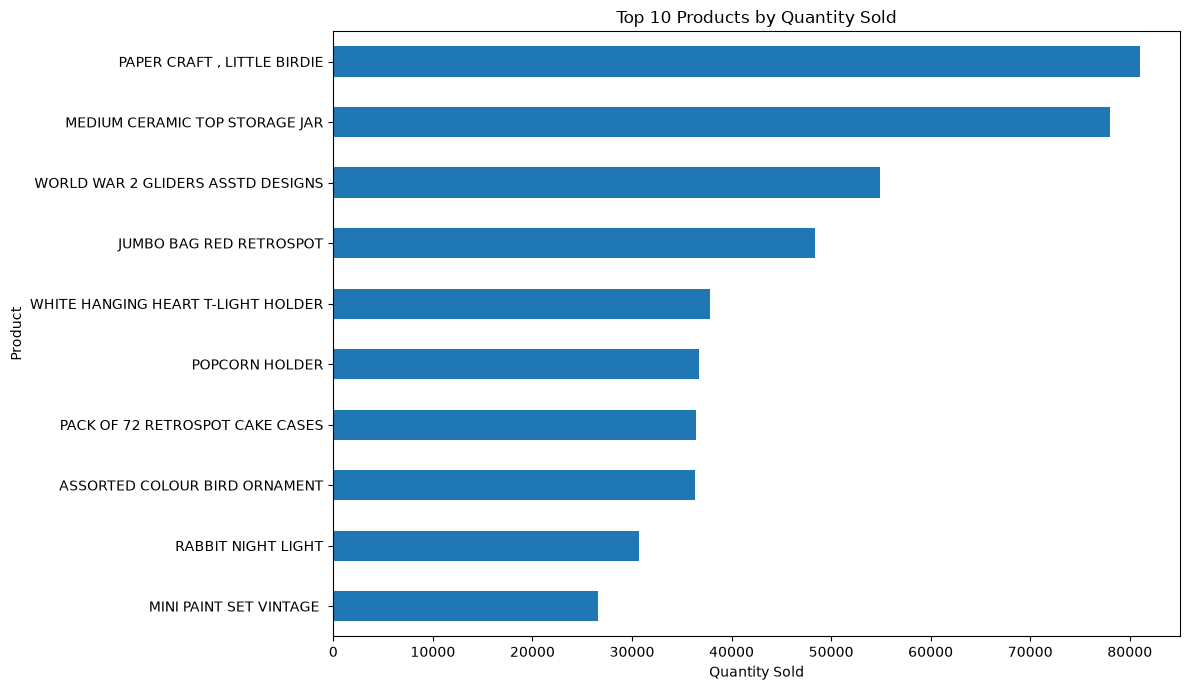

In [45]:
plt.figure(figsize=(12, 7))

top_products_quantity.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [46]:
top_products_revenue = (
    df_clean
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_revenue

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

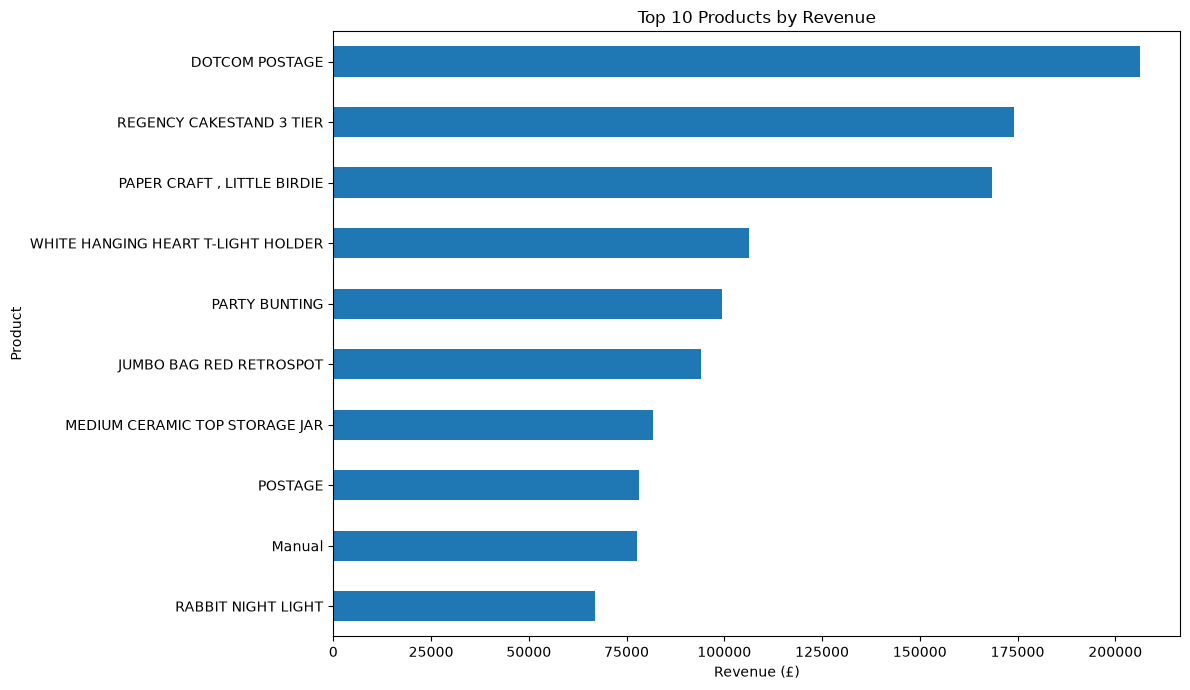

In [47]:
plt.figure(figsize=(12, 7))

top_products_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [48]:
country_revenue = (
    df_clean
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

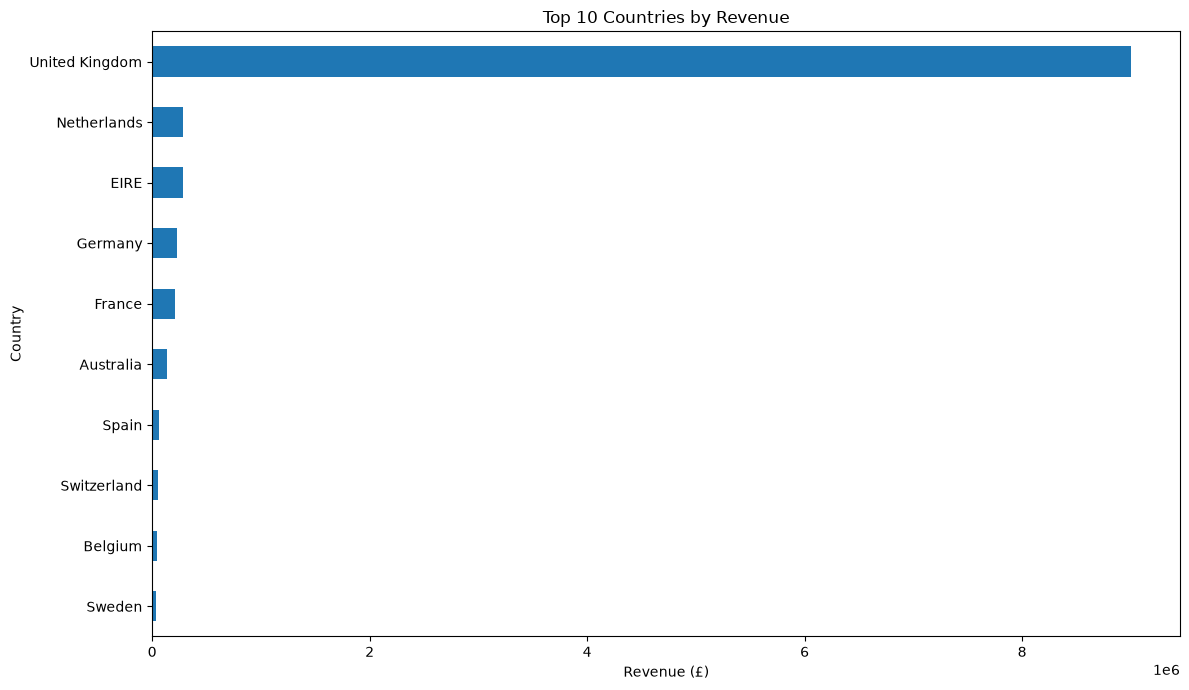

In [49]:
plt.figure(figsize=(12, 7))

country_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [50]:
country_orders = (
    df_clean
    .groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

country_orders.head(10)

Country
United Kingdom    18019
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          94
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64

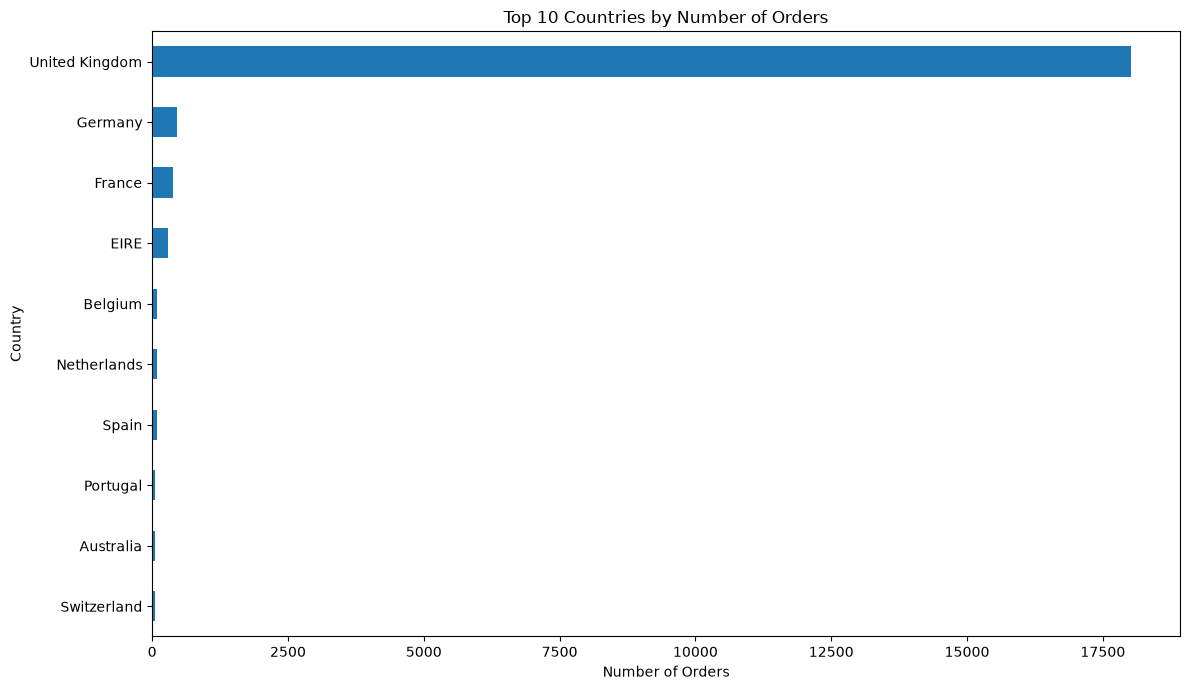

In [51]:
plt.figure(figsize=(12, 7))

country_orders.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [52]:
df_customer

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [54]:
df_customer = df_clean.dropna(
    subset=["CustomerID"]
).copy()

print("Customer dataset created successfully!")
print("Rows:", len(df_customer))

Customer dataset created successfully!
Rows: 392692


In [55]:
print(df_customer.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Date', 'Month']


In [56]:
customer_revenue = (
    df_customer
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

customer_revenue.head(10)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

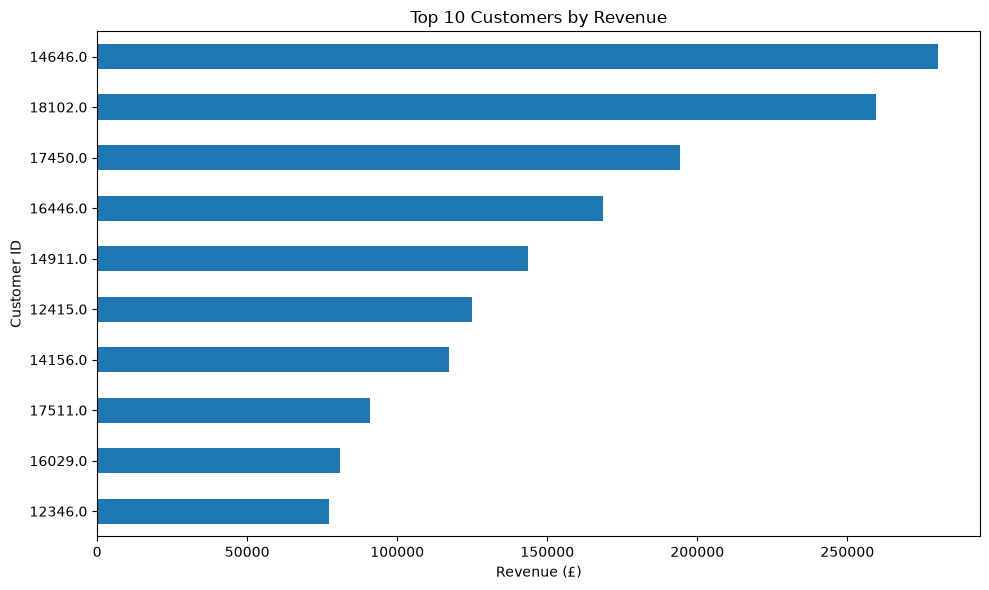

In [57]:
plt.figure(figsize=(10, 6))

customer_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [58]:
average_order_value = (
    total_revenue / total_orders
)

print(
    f"Average Order Value: £{average_order_value:,.2f}"
)

Average Order Value: £533.17


In [59]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Average Order Value",
        "Best Sales Month"
    ],
    "Value": [
        f"£{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"{total_customers:,}",
        f"{total_products:,}",
        f"£{average_order_value:,.2f}",
        str(best_month)
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,"£10,642,110.80"
1,Total Orders,"19,960"
2,Total Customers,"4,338"
3,Total Products,"3,922"
4,Average Order Value,£533.17
5,Best Sales Month,2011-11


In [60]:
monthly_revenue_ts = monthly_revenue.copy()

monthly_revenue_ts.index = (
    monthly_revenue_ts.index.to_timestamp()
)

moving_average_3m = (
    monthly_revenue_ts
    .rolling(window=3)
    .mean()
)

moving_average_3m

Month
2010-12-01             NaN
2011-01-01             NaN
2011-02-01    6.779366e+05
2011-03-01    6.428575e+05
2011-04-01    5.919098e+05
2011-05-01    6.741601e+05
2011-06-01    6.889374e+05
2011-07-01    7.493066e+05
2011-08-01    7.454882e+05
2011-09-01    8.441176e+05
2011-10-01    9.885134e+05
2011-11-01    1.237189e+06
2011-12-01    1.097640e+06
Freq: MS, Name: Revenue, dtype: float64

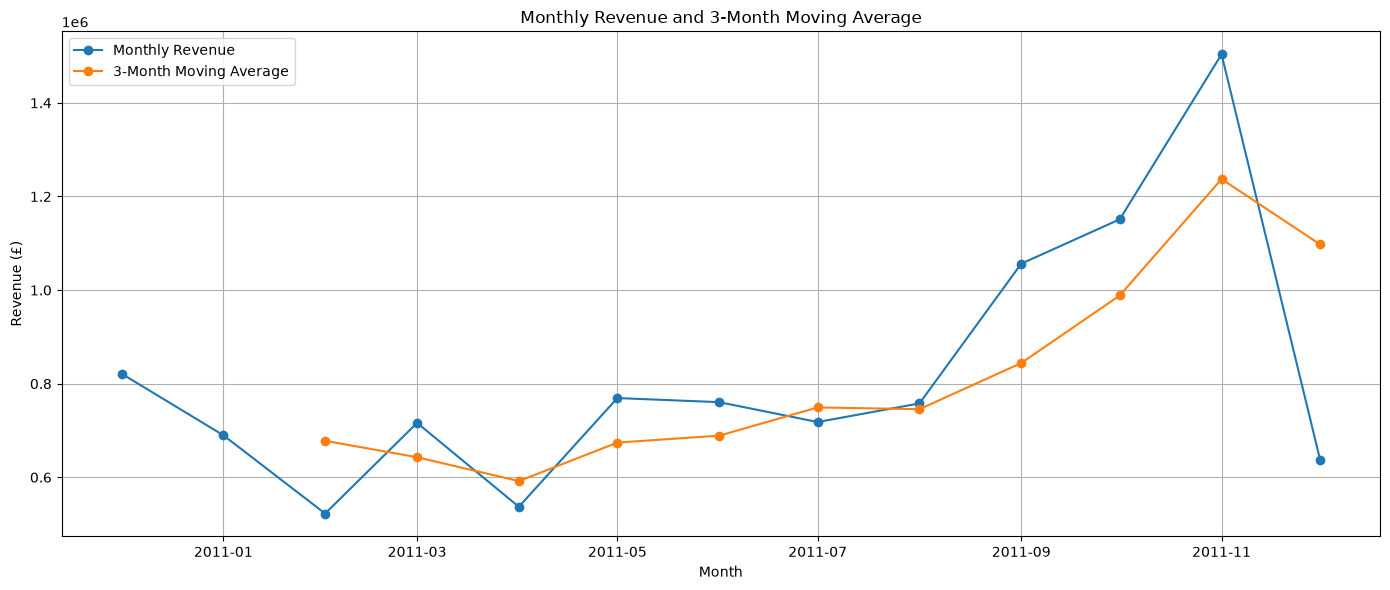

In [61]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue_ts.index,
    monthly_revenue_ts.values,
    marker="o",
    label="Monthly Revenue"
)

plt.plot(
    moving_average_3m.index,
    moving_average_3m.values,
    marker="o",
    label="3-Month Moving Average"
)

plt.title("Monthly Revenue and 3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [62]:
analysis_date = df_customer["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Analysis Date:", analysis_date)

Analysis Date: 2011-12-10 12:50:00


In [63]:
rfm = df_customer.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (
        analysis_date - x.max()
    ).days,

    "InvoiceNo": "nunique",

    "Revenue": "sum"
})

In [64]:
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

In [65]:
rfm.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [66]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [67]:
print("Invalid Recency:", (rfm["Recency"] < 0).sum())
print("Invalid Frequency:", (rfm["Frequency"] <= 0).sum())
print("Invalid Monetary:", (rfm["Monetary"] <= 0).sum())

Invalid Recency: 0
Invalid Frequency: 0
Invalid Monetary: 0


In [68]:
rfm_clean = rfm[
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

print("Customers available for segmentation:", len(rfm_clean))

Customers available for segmentation: 4338


In [69]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_clean[
        ["Recency", "Frequency", "Monetary"]
    ]
)

print("RFM data standardized successfully!")

RFM data standardized successfully!


In [70]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm_clean["Cluster"] = kmeans.fit_predict(
    rfm_scaled
)

print("Customer segmentation completed!")

Customer segmentation completed!


In [71]:
rfm_clean.head(10)

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,3
12347.0,2,7,4310.00,0
12348.0,75,4,1797.24,0
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,1
12352.0,36,8,2506.04,0
12353.0,204,1,89.00,1
12354.0,232,1,1079.40,1
12355.0,214,1,459.40,1


In [72]:
cluster_summary = (
    rfm_clean
    .groupby("Cluster")
    .agg({
        "Recency": "mean",
        "Frequency": "mean",
        "Monetary": "mean"
    })
    .round(2)
)

cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


In [73]:
cluster_counts = (
    rfm_clean["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_counts

Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64

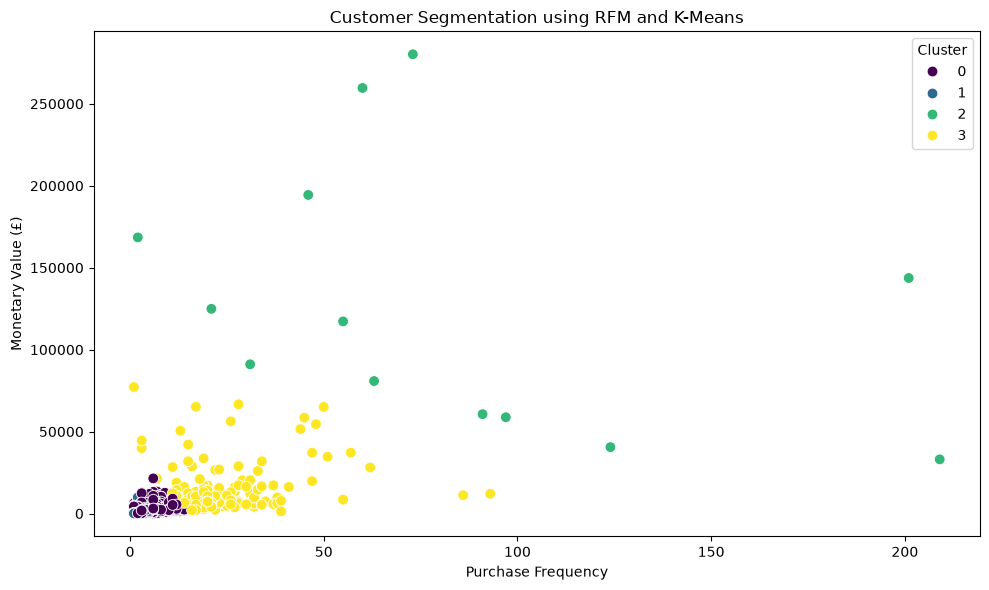

In [74]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_clean,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("Customer Segmentation using RFM and K-Means")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value (£)")

plt.tight_layout()
plt.show()

In [75]:
cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


In [76]:
cluster_percentage = (
    rfm_clean["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

cluster_percentage = cluster_percentage.round(2)

cluster_percentage

Cluster
0    70.4
1    24.6
2     0.3
3     4.7
Name: proportion, dtype: float64

In [77]:
segment_summary = cluster_summary.copy()

segment_summary["Customer Count"] = (
    cluster_counts
)

segment_summary["Customer Percentage"] = (
    cluster_percentage
)

segment_summary

,Recency,Frequency,Monetary,Customer Count,Customer Percentage
Cluster,,,,,
0,43.70,3.68,1353.63,3054,70.4
1,248.08,1.55,478.85,1067,24.6
2,7.38,82.54,127187.96,13,0.3
3,15.50,22.33,12690.50,204,4.7


In [78]:
high_value_customers = (
    rfm_clean
    .sort_values("Monetary", ascending=False)
    .head(20)
)

high_value_customers

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
14646.0,2,73,280206.02,2
18102.0,1,60,259657.30,2
17450.0,8,46,194390.79,2
16446.0,1,2,168472.50,2
14911.0,1,201,143711.17,2
12415.0,24,21,124914.53,2
14156.0,10,55,117210.08,2
17511.0,3,31,91062.38,2
16029.0,39,63,80850.84,2


In [79]:
rfm_output = r"D:\Sagha Documents\Retail_Analytics_Project\customer_rfm_segmentation.csv"

rfm_clean.to_csv(
    rfm_output
)

print("RFM segmentation saved successfully!")

RFM segmentation saved successfully!


In [80]:
basket_data = df_clean[
    df_clean["Country"] == "United Kingdom"
].copy()

print("UK transaction rows:", len(basket_data))

UK transaction rows: 479985


In [81]:
basket = (
    basket_data
    .groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack()
    .fillna(0)
)

print("Basket shape:", basket.shape)

Basket shape: (18019, 4007)


In [83]:
basket_binary = (basket > 0).astype(int)

basket_binary.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,TOADSTOOL BEDSIDE LIGHT,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [84]:
print("Basket shape:", basket_binary.shape)

print("\nUnique values:")
print(basket_binary.stack().unique())

Basket shape: (18019, 4007)

Unique values:
[0 1]


In [85]:
frequent_items = apriori(
    basket_binary,
    min_support=0.02,
    use_colnames=True
)

print(
    "Number of frequent itemsets:",
    len(frequent_items)
)

Number of frequent itemsets: 400


In [86]:
frequent_items.sort_values(
    "support",
    ascending=False
).head(10)

,support,itemsets
280,0.119984,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
109,0.107387,frozenset({JUMBO BAG RED RETROSPOT})
204,0.093512,frozenset({REGENCY CAKESTAND 3 TIER})
165,0.088407,frozenset({PARTY BUNTING})
135,0.077252,frozenset({LUNCH BAG RED RETROSPOT})
17,0.076086,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
224,0.068872,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN })
147,0.067651,frozenset({NATURAL SLATE HEART CHALKBOARD })
128,0.067484,frozenset({LUNCH BAG BLACK SKULL.})
88,0.064598,frozenset({HEART OF WICKER SMALL})


In [87]:
rules = association_rules(
    frequent_items,
    metric="lift",
    min_threshold=1.0
)

print("Number of association rules:", len(rules))

Number of association rules: 218


In [88]:
rules_summary = rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()

rules_summary.head()

,antecedents,consequents,support,confidence,lift
0,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),frozenset({60 TEATIME FAIRY CAKE CASES}),0.022698,0.362267,8.668922
1,frozenset({60 TEATIME FAIRY CAKE CASES}),frozenset({PACK OF 72 RETROSPOT CAKE CASES}),0.022698,0.543161,8.668922
2,frozenset({ALARM CLOCK BAKELIKE GREEN}),frozenset({ALARM CLOCK BAKELIKE RED }),0.031245,0.642694,12.452370
3,frozenset({ALARM CLOCK BAKELIKE RED }),frozenset({ALARM CLOCK BAKELIKE GREEN}),0.031245,0.605376,12.452370
4,frozenset({ALARM CLOCK BAKELIKE PINK}),frozenset({ALARM CLOCK BAKELIKE RED }),0.021810,0.599085,11.607440


In [89]:
rules_by_lift = rules_summary.sort_values(
    "lift",
    ascending=False
)

rules_by_lift.head(10)

,antecedents,consequents,support,confidence,lift
193,frozenset({WOODEN HEART CHRISTMAS SCANDINAVIAN}),frozenset({WOODEN STAR CHRISTMAS SCANDINAVIAN}),0.020423,0.722986,27.197263
192,frozenset({WOODEN STAR CHRISTMAS SCANDINAVIAN}),frozenset({WOODEN HEART CHRISTMAS SCANDINAVIAN}),0.020423,0.768267,27.197263
197,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",0.027305,0.700855,18.041001
196,"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.027305,0.702857,18.041001
195,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.027305,0.902752,17.453534
198,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.027305,0.527897,17.453534
194,"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",frozenset({ROSES REGENCY TEACUP AND SAUCER }),0.027305,0.854167,16.099612
199,frozenset({ROSES REGENCY TEACUP AND SAUCER }),"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",0.027305,0.514644,16.099612
33,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.031966,0.618026,15.863541
32,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.031966,0.820513,15.863541


In [90]:
def format_itemset(itemset):
    return ", ".join(sorted(itemset))


rules_readable = rules_by_lift.copy()

rules_readable["antecedents"] = (
    rules_readable["antecedents"]
    .apply(format_itemset)
)

rules_readable["consequents"] = (
    rules_readable["consequents"]
    .apply(format_itemset)
)

rules_readable.head(10)

,antecedents,consequents,support,confidence,lift
193,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020423,0.722986,27.197263
192,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020423,0.768267,27.197263
197,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027305,0.700855,18.041001
196,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027305,0.702857,18.041001
195,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027305,0.902752,17.453534
198,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.027305,0.527897,17.453534
194,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027305,0.854167,16.099612
199,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.027305,0.514644,16.099612
33,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031966,0.618026,15.863541
32,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031966,0.820513,15.863541


In [91]:
strong_rules = rules_readable[
    (rules_readable["confidence"] >= 0.5) &
    (rules_readable["lift"] > 1)
].copy()

strong_rules.head(10)

,antecedents,consequents,support,confidence,lift
193,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020423,0.722986,27.197263
192,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020423,0.768267,27.197263
197,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027305,0.700855,18.041001
196,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027305,0.702857,18.041001
195,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027305,0.902752,17.453534
198,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.027305,0.527897,17.453534
194,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027305,0.854167,16.099612
199,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.027305,0.514644,16.099612
33,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031966,0.618026,15.863541
32,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031966,0.820513,15.863541


In [92]:
strong_rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].head(15)

,antecedents,consequents,support,confidence,lift
193,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020423,0.722986,27.197263
192,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020423,0.768267,27.197263
197,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027305,0.700855,18.041001
196,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027305,0.702857,18.041001
195,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027305,0.902752,17.453534
198,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.027305,0.527897,17.453534
194,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027305,0.854167,16.099612
199,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.027305,0.514644,16.099612
33,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031966,0.618026,15.863541
32,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031966,0.820513,15.863541


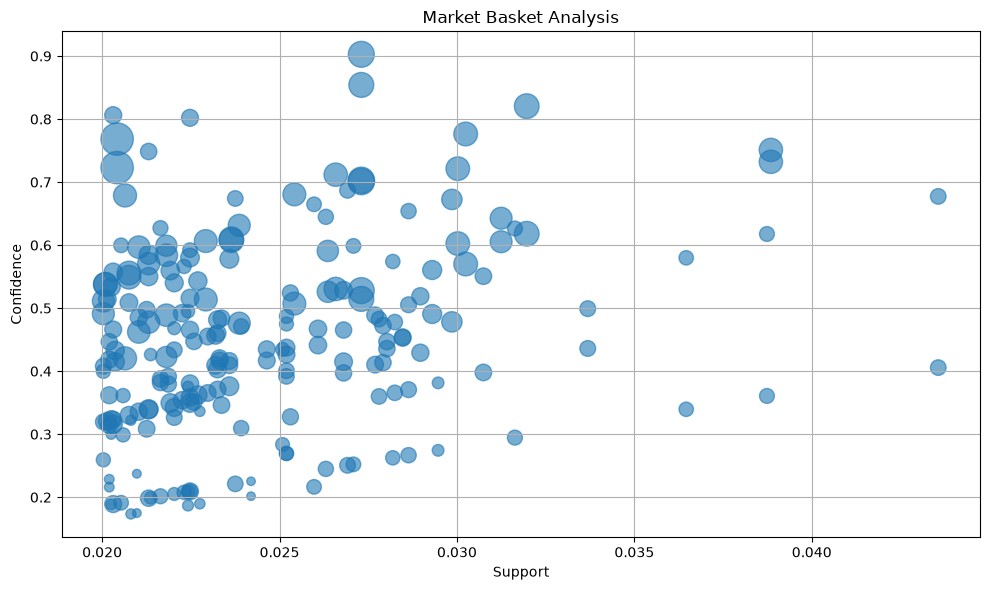

In [93]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rules["support"],
    rules["confidence"],
    s=rules["lift"] * 20,
    alpha=0.6
)

plt.title("Market Basket Analysis")
plt.xlabel("Support")
plt.ylabel("Confidence")

plt.grid(True)
plt.tight_layout()
plt.show()

In [94]:
market_basket_file = (
    r"D:\Sagha Documents\Retail_Analytics_Project"
    r"\market_basket_rules.csv"
)

rules_readable.to_csv(
    market_basket_file,
    index=False
)

print("Market basket results saved successfully!")

Market basket results saved successfully!


In [95]:
print("=" * 55)
print("             RETAIL ANALYTICS SUMMARY")
print("=" * 55)

print(f"Total Revenue       : £{total_revenue:,.2f}")
print(f"Total Orders        : {total_orders:,}")
print(f"Total Customers     : {total_customers:,}")
print(f"Total Products      : {total_products:,}")
print(f"Average Order Value : £{average_order_value:,.2f}")

print("=" * 55)

             RETAIL ANALYTICS SUMMARY
Total Revenue       : £10,642,110.80
Total Orders        : 19,960
Total Customers     : 4,338
Total Products      : 3,922
Average Order Value : £533.17


In [96]:
top_country = country_revenue.idxmax()
top_country_revenue = country_revenue.max()

print("Top Revenue Country:", top_country)
print(f"Revenue: £{top_country_revenue:,.2f}")

Top Revenue Country: United Kingdom
Revenue: £9,001,744.09


In [97]:
top_product = top_products_revenue.index[0]
top_product_revenue = top_products_revenue.iloc[0]

print("Top Product:", top_product)
print(f"Revenue: £{top_product_revenue:,.2f}")

Top Product: DOTCOM POSTAGE
Revenue: £206,248.77


In [98]:
print("Best Sales Month:", best_month)
print(f"Revenue: £{best_month_revenue:,.2f}")

Best Sales Month: 2011-11
Revenue: £1,503,866.78


In [99]:
insights = pd.DataFrame({
    "Analysis": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Average Order Value",
        "Top Revenue Country",
        "Top Revenue Product",
        "Best Sales Month"
    ],
    "Result": [
        f"£{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"{total_customers:,}",
        f"£{average_order_value:,.2f}",
        top_country,
        top_product,
        str(best_month)
    ]
})

insights

,Analysis,Result
0,Total Revenue,"£10,642,110.80"
1,Total Orders,"19,960"
2,Total Customers,"4,338"
3,Average Order Value,£533.17
4,Top Revenue Country,United Kingdom
5,Top Revenue Product,DOTCOM POSTAGE
6,Best Sales Month,2011-11


In [100]:
cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


In [101]:
rules_readable.head(10)

,antecedents,consequents,support,confidence,lift
193,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020423,0.722986,27.197263
192,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020423,0.768267,27.197263
197,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027305,0.700855,18.041001
196,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027305,0.702857,18.041001
195,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027305,0.902752,17.453534
198,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.027305,0.527897,17.453534
194,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027305,0.854167,16.099612
199,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.027305,0.514644,16.099612
33,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031966,0.618026,15.863541
32,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031966,0.820513,15.863541


In [102]:
insights

,Analysis,Result
0,Total Revenue,"£10,642,110.80"
1,Total Orders,"19,960"
2,Total Customers,"4,338"
3,Average Order Value,£533.17
4,Top Revenue Country,United Kingdom
5,Top Revenue Product,DOTCOM POSTAGE
6,Best Sales Month,2011-11


In [103]:
cluster_names = {
    0: "Regular Customers",
    1: "At-Risk / Inactive Customers",
    2: "VIP Customers",
    3: "Loyal High-Value Customers"
}

rfm_clean["Customer Segment"] = (
    rfm_clean["Cluster"].map(cluster_names)
)

rfm_clean.head()

,Recency,Frequency,Monetary,Cluster,Customer Segment
CustomerID,,,,,
12346.0,326,1,77183.60,3,Loyal High-Value Customers
12347.0,2,7,4310.00,0,Regular Customers
12348.0,75,4,1797.24,0,Regular Customers
12349.0,19,1,1757.55,0,Regular Customers
12350.0,310,1,334.40,1,At-Risk / Inactive Customers


In [105]:
final_segment_summary = (
    rfm_clean
    .groupby("Customer Segment")
    .agg(
        Customers=("Recency", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .round(2)
    .sort_values("Average_Monetary", ascending=False)
)

final_segment_summary

,Customers,Average_Recency,Average_Frequency,Average_Monetary
Customer Segment,,,,
VIP Customers,13,7.38,82.54,127187.96
Loyal High-Value Customers,204,15.50,22.33,12690.50
Regular Customers,3054,43.70,3.68,1353.63
At-Risk / Inactive Customers,1067,248.08,1.55,478.85


In [106]:
service_items = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "MANUAL",
    "AMAZON FEE",
    "BANK CHARGES"
]

physical_products = df_clean[
    ~df_clean["Description"].isin(service_items)
].copy()

physical_product_revenue = (
    physical_products
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

physical_product_revenue.head(10)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
Name: Revenue, dtype: float64

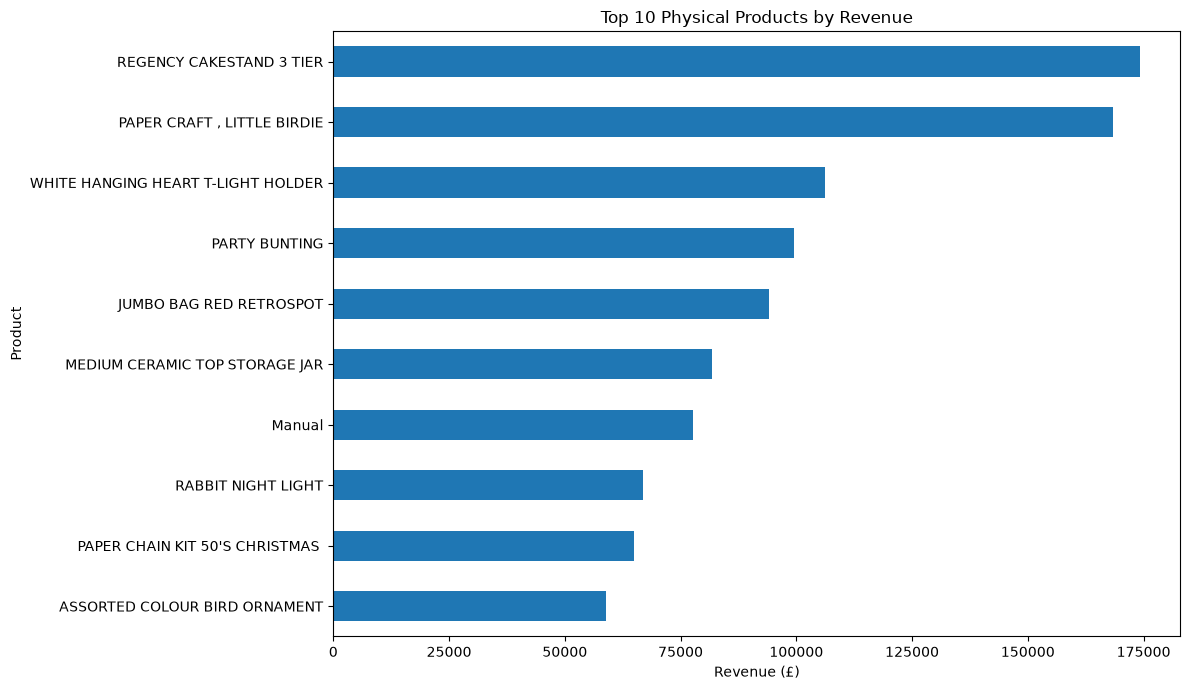

In [107]:
plt.figure(figsize=(12, 7))

physical_product_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Physical Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

## Business Insights

### 1. Overall Revenue Performance

The analyzed retail transactions generated a total revenue of £10.64 million across 19,960 orders and 4,338 unique customers. The average order value was approximately £533.17.

### 2. Geographic Performance

The United Kingdom generated the highest revenue among the countries represented in the dataset, indicating that it was the primary market for the retailer.

### 3. Seasonal Sales Performance

November 2011 was the highest-revenue month in the analyzed period. This indicates increased customer purchasing activity toward the end of the year.

### 4. Customer Segmentation

RFM analysis combined with K-Means clustering identified four customer segments:

- VIP Customers
- Loyal High-Value Customers
- Regular Customers
- At-Risk / Inactive Customers

The VIP segment showed the highest purchase frequency and monetary value, making customer retention particularly important for this group.

### 5. At-Risk Customers

The At-Risk / Inactive segment had substantially higher recency and lower frequency and monetary values. These customers may benefit from targeted re-engagement campaigns.

### 6. Product Associations

Market Basket Analysis identified strong associations between several product combinations, particularly Christmas-themed products and Regency-style tea products. These associations can support cross-selling and product bundling strategies.

## Business Recommendations

1. **Retain VIP Customers**

   The VIP customer segment contributes exceptionally high monetary value. The business should prioritize retention through personalized offers, loyalty programs, and exclusive promotions.

2. **Reactivate At-Risk Customers**

   Customers with high recency and low purchase frequency should receive targeted re-engagement campaigns such as personalized discounts, reminders, and new-product promotions.

3. **Use Product Bundling**

   Strong product associations discovered through Market Basket Analysis can be used to create bundles and cross-selling recommendations.

4. **Prepare for Seasonal Demand**

   November recorded the highest revenue. Inventory and marketing campaigns should therefore be planned ahead of high-demand periods.

5. **Focus on the UK Market**

   Since the United Kingdom generated the highest revenue, maintaining strong customer engagement and product availability in this market should remain a priority.

6. **Use Customer Segmentation for Marketing**

   Different customer segments should receive different marketing strategies rather than using a single promotion for all customers.

## Conclusion

This project analyzed real-world online retail transaction data using Python and data science techniques.

The analysis involved data cleaning, exploratory data analysis, revenue analysis, customer analysis, product analysis, geographic analysis, RFM customer segmentation, K-Means clustering, and Market Basket Analysis.

The analysis identified important business patterns including total revenue of £10.64 million, 19,960 orders, 4,338 customers, and an average order value of approximately £533.17.

Customer segmentation revealed distinct groups ranging from highly valuable VIP customers to inactive customers. Market Basket Analysis also identified strong relationships between products, providing opportunities for cross-selling and product bundling.

Overall, the project demonstrates how data analytics and machine learning techniques can transform raw retail transaction data into actionable business insights.

In [108]:
service_items = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "MANUAL",
    "AMAZON FEE",
    "BANK CHARGES"
]

physical_products = df_clean[
    ~df_clean["Description"].isin(service_items)
].copy()

print("Physical product transactions:", len(physical_products))

Physical product transactions: 523044


In [109]:
physical_product_revenue = (
    physical_products
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

physical_product_revenue.head(10)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
Name: Revenue, dtype: float64

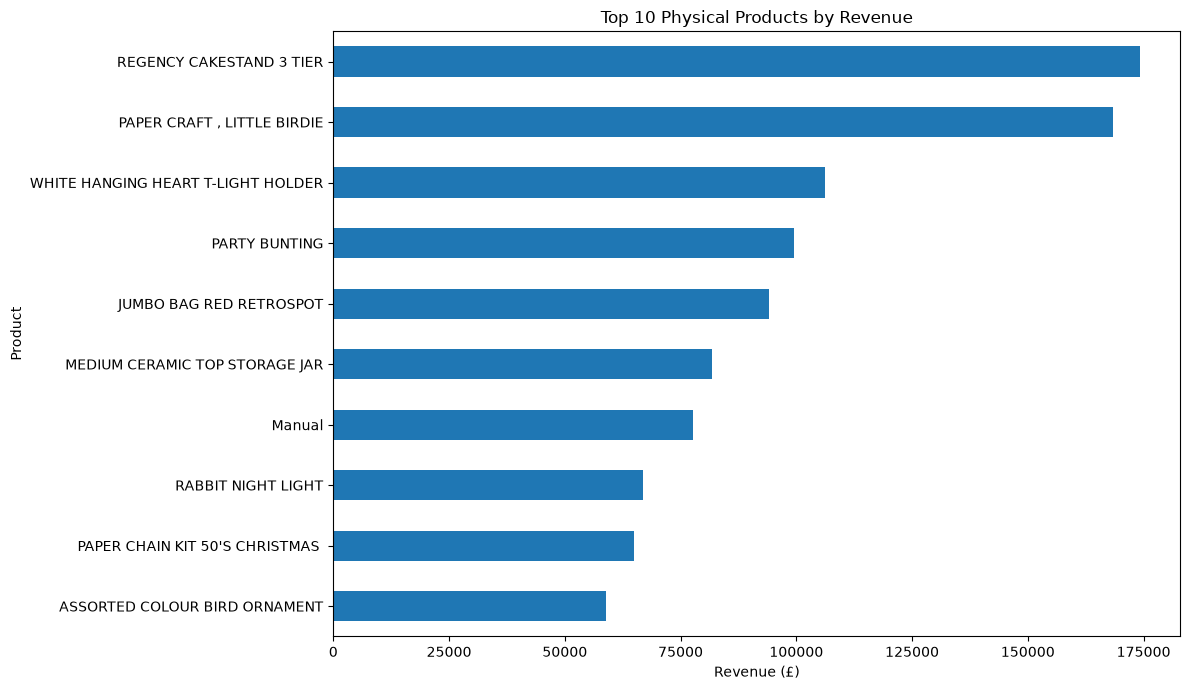

In [110]:
plt.figure(figsize=(12, 7))

physical_product_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Physical Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [111]:
physical_product_quantity = (
    physical_products
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

physical_product_quantity.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

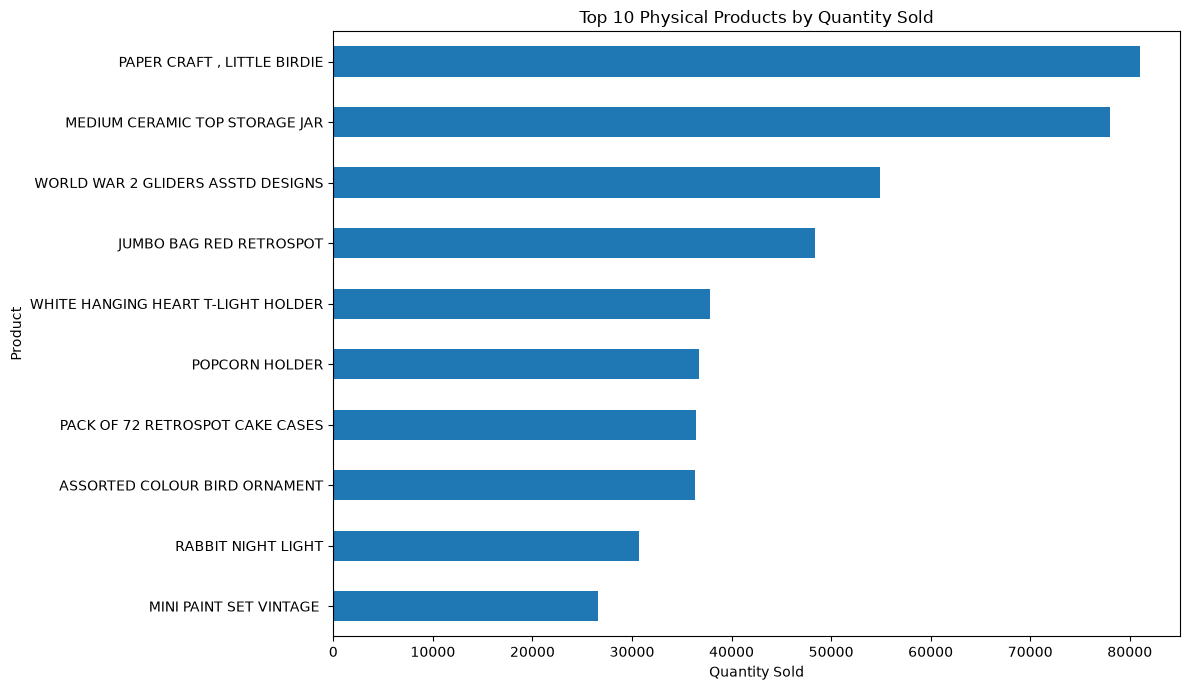

In [112]:
plt.figure(figsize=(12, 7))

physical_product_quantity.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Physical Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [114]:
final_kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Average Order Value",
        "Top Revenue Country",
        "Best Sales Month"
    ],
    "Value": [
        f"£{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"{total_customers:,}",
        f"{total_products:,}",
        f"£{average_order_value:,.2f}",
        top_country,
        str(best_month)
    ]
})

final_kpis

,KPI,Value
0,Total Revenue,"£10,642,110.80"
1,Total Orders,"19,960"
2,Total Customers,"4,338"
3,Total Products,"3,922"
4,Average Order Value,£533.17
5,Top Revenue Country,United Kingdom
6,Best Sales Month,2011-11


In [115]:
final_segment_summary

,Customers,Average_Recency,Average_Frequency,Average_Monetary
Customer Segment,,,,
VIP Customers,13,7.38,82.54,127187.96
Loyal High-Value Customers,204,15.50,22.33,12690.50
Regular Customers,3054,43.70,3.68,1353.63
At-Risk / Inactive Customers,1067,248.08,1.55,478.85


In [116]:
final_segment_summary.round(2)

,Customers,Average_Recency,Average_Frequency,Average_Monetary
Customer Segment,,,,
VIP Customers,13,7.38,82.54,127187.96
Loyal High-Value Customers,204,15.50,22.33,12690.50
Regular Customers,3054,43.70,3.68,1353.63
At-Risk / Inactive Customers,1067,248.08,1.55,478.85


In [117]:
final_market_basket = rules_readable[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].head(10).copy()

final_market_basket

,antecedents,consequents,support,confidence,lift
193,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020423,0.722986,27.197263
192,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020423,0.768267,27.197263
197,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027305,0.700855,18.041001
196,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027305,0.702857,18.041001
195,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027305,0.902752,17.453534
198,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.027305,0.527897,17.453534
194,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027305,0.854167,16.099612
199,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.027305,0.514644,16.099612
33,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031966,0.618026,15.863541
32,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031966,0.820513,15.863541


In [118]:
final_market_basket[
    ["support", "confidence", "lift"]
] = final_market_basket[
    ["support", "confidence", "lift"]
].round(3)

final_market_basket

,antecedents,consequents,support,confidence,lift
193,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020,0.723,27.197
192,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020,0.768,27.197
197,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027,0.701,18.041
196,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027,0.703,18.041
195,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027,0.903,17.454
198,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.027,0.528,17.454
194,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027,0.854,16.100
199,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.027,0.515,16.100
33,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.032,0.618,15.864
32,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.032,0.821,15.864


In [119]:
project_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Average Order Value",
        "Top Revenue Country",
        "Best Sales Month"
    ],
    "Result": [
        f"£{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"{total_customers:,}",
        f"{total_products:,}",
        f"£{average_order_value:,.2f}",
        top_country,
        str(best_month)
    ]
})

project_summary

,Metric,Result
0,Total Revenue,"£10,642,110.80"
1,Total Orders,"19,960"
2,Total Customers,"4,338"
3,Total Products,"3,922"
4,Average Order Value,£533.17
5,Top Revenue Country,United Kingdom
6,Best Sales Month,2011-11


In [120]:
project_summary.to_csv(
    r"D:\Sagha Documents\Retail_Analytics_Project\project_summary.csv",
    index=False
)

print("Project summary saved successfully!")

Project summary saved successfully!


In [121]:
final_market_basket.to_csv(
    r"D:\Sagha Documents\Retail_Analytics_Project\final_market_basket.csv",
    index=False
)

print("Final market basket results saved!")

Final market basket results saved!


## Project Workflow

The project follows the following end-to-end workflow:

**Data Collection**
↓
**Data Understanding**
↓
**Data Cleaning**
↓
**Feature Engineering**
↓
**Exploratory Data Analysis**
↓
**Sales & Revenue Analysis**
↓
**Customer Analysis**
↓
**RFM Customer Segmentation**
↓
**K-Means Clustering**
↓
**Market Basket Analysis**
↓
**Business Insights**
↓
**Business Recommendations**
↓
**Conclusion**

# Key Results

| Metric | Result |
|---|---:|
| Total Revenue | £10,642,110.80 |
| Total Orders | 19,960 |
| Total Customers | 4,338 |
| Average Order Value | £533.17 |
| Top Revenue Country | United Kingdom |
| Best Sales Month | November 2011 |

### Customer Segmentation

Four major customer groups were identified:

1. **VIP Customers** – extremely high purchase frequency and monetary value.
2. **Loyal High-Value Customers** – frequent and valuable customers with strong recent activity.
3. **Regular Customers** – moderate purchasing behavior.
4. **At-Risk / Inactive Customers** – customers with long periods since their last purchase and relatively low spending.

### Market Basket Analysis

Strong associations were identified between several products, including Christmas-themed products and Regency-style tea products. These relationships can support cross-selling and product bundling strategies.

# Limitations

1. The dataset represents historical transactions and may not reflect current customer behavior.

2. Some transactions contain missing CustomerID values, so customer-level analysis was performed only on records with available customer identifiers.

3. The dataset contains service-related transaction descriptions such as postage, which were excluded when identifying physical retail products.

4. K-Means clustering requires selecting a number of clusters. Four clusters were used for this project to create interpretable customer segments.

5. Association rules identify relationships between products but do not establish causal relationships.

6. The analysis focuses on descriptive and exploratory insights rather than forecasting future sales.

# Future Scope

The project can be extended in several ways:

- Develop a sales forecasting model.
- Predict customer churn.
- Build a recommendation system.
- Apply advanced customer lifetime value analysis.
- Create an interactive Power BI or Tableau dashboard.
- Compare different clustering algorithms.
- Use more recent retail data for real-time analysis.
- Develop a machine-learning model to predict future customer purchases.

# Final Conclusion

This project successfully demonstrated an end-to-end real-world retail analytics workflow using Python.

The analysis transformed raw transaction data into meaningful business information through data cleaning, exploratory analysis, visualization, customer segmentation, and market basket analysis.

The retailer generated approximately £10.64 million in analyzed revenue from 19,960 orders and 4,338 customers. The analysis identified the United Kingdom as the highest-revenue country and November 2011 as the highest-revenue month.

RFM analysis combined with K-Means clustering identified four distinct customer groups, including VIP, Loyal High-Value, Regular, and At-Risk / Inactive customers.

Market Basket Analysis identified strong product relationships that could be used for cross-selling and product bundling.

Overall, the project demonstrates how data science techniques can be applied to real-world retail data to support customer management, sales optimization, marketing strategies, and business decision-making.